# Этап 2. Разведочный анализ данных (EDA)
## Модуль: 02_eda_features — Анализ признаков, связь с целевой переменной и отбор лучших признаков
### Проект: Bitcoin AML Detection (Анализ подозрительных транзакций в графе Bitcoin)

**Цель модуля:**
1. Оценить прогностическую способность пространства признаков (`LOCAL_FEATURES` vs `AGG_FEATURES`) методами базовой описательной статистики (инструментарий 1-й недели).
2. Измерить монотонную и линейную связь каждого признака с целевой переменной с помощью **корреляций Спирмена и Пирсона**.
3. Построить сводные таблицы средних, медиан и вариативности признаков в разрезе классов (`Licit` vs `Illicit`).
4. Исследовать скошенность распределений (`skewness`), тяжелые хвосты и эффект логарифмирования (`np.log1p`).
5. Оценить распределение выбросов по классам через **межквартильный размах ($1.5 \times IQR$)**.
6. Провести квантильный анализ риска (`pd.qcut`) и сформировать рейтинг топ-признаков для последующего моделирования.

In [2]:
import sys
import os

# Добавляем родительскую директорию (корень проекта) в путь поиска модулей
sys.path.append(os.path.abspath('..')) 

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Импорт из модуля команды проекта
try:
    from src.bitcoin_aml_detection.data import AGG_FEATURES, FEATURES, LOCAL_FEATURES, load_edges, load_txs
    LOADER_AVAILABLE = True
except ImportError:
    LOADER_AVAILABLE = False
    print("Внимание: Пакет bitcoin_aml_detection не найден в окружении. Используется демонстрационная генерация данных.")

# Настройки визуализации Seaborn
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10

### 1. Загрузка данных и выделение размеченной выборки
В датасете Elliptic класс транзакции закодирован в поле `class`:
* `1`: **Illicit** (мошенническая / подозрительная транзакция — наш целевой класс `1`).
* `2`: **Licit** (подтвержденная легальная операция — класс `0`).
* `'unknown'`: неразмеченная транзакция (подлежит отдельному анализу коллегой в модуле `02_eda_target_time`).

Для оценки связи признаков с таргетом отфильтруем размеченные объекты.

In [3]:
if LOADER_AVAILABLE:
    df = load_txs()
else:
    # Синтетический датасет для отладки структуры, если модуль не установлен локально
    np.random.seed(42)
    LOCAL_FEATURES = [f"local_feat_{i}" for i in range(12)]
    AGG_FEATURES = [f"agg_feat_{i}" for i in range(12)]
    FEATURES = LOCAL_FEATURES + AGG_FEATURES
    n = 4000
    mock_dict = {f: np.random.exponential(scale=2.0, size=n) for f in FEATURES}
    # Делаем часть признаков коррелирующими с таргетом
    mock_dict['class'] = np.random.choice(['1', '2', 'unknown'], size=n, p=[0.1, 0.45, 0.45])
    df = pd.DataFrame(mock_dict)

print(f"Форма исходного датасета: {df.shape}")
print(f"Число признаков: Local = {len(LOCAL_FEATURES)}, Aggregated = {len(AGG_FEATURES)}, Всего = {len(FEATURES)}")

Форма исходного датасета: (203769, 169)
Число признаков: Local = 93, Aggregated = 72, Всего = 165


In [4]:
# 1. Поиск целевой колонки
target_col = None
for col in ['class', 'target', 'label', 'illicit']:
    if col in df.columns:
        target_col = col
        break

if target_col is None:
    raise KeyError("Колонка с разметкой классов не обнаружена в df")

print(f"Используем колонку таргета: '{target_col}'")
print("Исходные значения в колонке:")
print(df[target_col].value_counts(dropna=False))

# 2. Универсальное приведение к бинарному таргету (1 — Illicit/мошенничество, 0 — Licit/легальная)
# Приводим к нижнему регистру и строке для надежности
s = df[target_col].astype(str).str.lower().str.strip()

mapping = {
    # Если разметка строковая
    'illicit': 1, 'licit': 0,
    # Если разметка оригинальная из Elliptic (1 - illicit, 2 - licit)
    '1': 1, '2': 0, '1.0': 1, '2.0': 0,
    # Если коллега уже закодировал в 0 и 1
    '0': 0, '0.0': 0
}

# 3. Фильтруем только те строки, которые распознались как 0 или 1 (unknown и NaN отсеются)
df_labeled = df.copy()
df_labeled['target'] = s.map(mapping)
df_labeled = df_labeled.dropna(subset=['target'])
df_labeled['target'] = df_labeled['target'].astype(int)

# 4. Проверка результата
print(f"\nУспешно отфильтровано размеченных строк: {df_labeled.shape}")
class_counts = df_labeled['target'].value_counts()
class_props = df_labeled['target'].value_counts(normalize=True) * 100

pd.DataFrame({
    'Количество': class_counts,
    'Доля (%)': class_props.round(2)
}).rename(index={1: 'Illicit (Мошеннические, 1)', 0: 'Licit (Легальные, 0)'})

Используем колонку таргета: 'label'
Исходные значения в колонке:
label
unknown    157205
licit       42019
illicit      4545
Name: count, dtype: int64

Успешно отфильтровано размеченных строк: (46564, 170)


,Количество,Доля (%)
target,,
"Licit (Легальные, 0)",42019,90.24
"Illicit (Мошеннические, 1)",4545,9.76


## 2. Анализ связи признаков с таргетом: Корреляции Пирсона и Спирмена
В соответствии с материалом Week 1, базовым инструментом оценки связи числовых признаков с таргетом являются коэффициенты корреляции:
- **Корреляция Пирсона ($r$)**: оценивает строго линейную связь (чувствительна к выбросам и ненормальности распределений).
- **Корреляция Спирмена ($\rho$)**: ранговая корреляция, оценивающая любую монотонную зависимость (устойчива к аномалиям и тяжелым хвостам транзакционных данных).

In [5]:
available_features = [f for f in FEATURES if f in df_labeled.columns]

# Расчет корреляций со всеми признаками через векторный corrwith()
pearson_corr = df_labeled[available_features].corrwith(df_labeled['target'], method='pearson')
spearman_corr = df_labeled[available_features].corrwith(df_labeled['target'], method='spearman')

# Формируем сводный датафрейм
corr_df = pd.DataFrame({
    'group': ['Local' if f in LOCAL_FEATURES else 'Aggregated' for f in available_features],
    'pearson': pearson_corr,
    'spearman': spearman_corr,
    'abs_spearman': spearman_corr.abs(),
    'abs_pearson': pearson_corr.abs()
}, index=available_features).sort_values(by='abs_spearman', ascending=False)

print("Топ-10 признаков по силе монотонной связи с таргетом (|Spearman|):")
corr_df.head(10)

Топ-10 признаков по силе монотонной связи с таргетом (|Spearman|):


,group,pearson,spearman,abs_spearman,abs_pearson
local_14,Local,-0.016227,-0.417098,0.417098,0.016227
local_5,Local,-0.016233,-0.417030,0.417030,0.016233
local_90,Local,-0.221294,-0.353160,0.353160,0.221294
local_53,Local,-0.261472,-0.345146,0.345146,0.261472
local_55,Local,-0.227146,-0.333374,0.333374,0.227146
local_66,Local,-0.105796,-0.329627,0.329627,0.105796
local_60,Local,-0.105803,-0.329609,0.329609,0.105803
local_29,Local,-0.094737,-0.326249,0.326249,0.094737
local_23,Local,-0.094741,-0.326239,0.326239,0.094741
agg_39,Aggregated,-0.045763,-0.324176,0.324176,0.045763


> **Интерпретация результатов скрининга:**
> 1. **Топ-предикторы:** Наиболее сильными монотонными факторами выступают `local_14` и `local_5` ($|\rho| \approx 0.42$).
> 2. **Нелинейность:** Разрыв между Пирсоном ($r \approx -0.016$) и Спирменом ($\rho \approx -0.417$) указывает на сильную асимметрию данных и нелинейность зависимости — требуется логарифмирование (`log1p`).
> 3. **Вектор риска:** Отрицательный знак всех топ-корреляций подтверждает, что мошеннические операции концентрируются в области минимальных значений локальных метрик транзакций.
> 4. **Коллинеарность:** Выявлены группы парных признаков (`local_14`/`local_5`, `local_66`/`local_60`), требующие проверки на избыточность в модуле корреляционного анализа.

### Сравнение групп признаков: Local Features vs Aggregated Features
Сравним распределение абсолютных коэффициентов корреляции Спирмена в разрезе локальных признаков транзакции и агрегатов по графу транзакций.

abs_spearman                                 abs_pearson         \
                  count    mean  median     std     max       count   mean   
group                                                                        
Aggregated           72  0.0863  0.0374  0.0957  0.3242          72  0.047   
Local                93  0.1538  0.1190  0.1125  0.4171          93  0.067   

                                    
            median     std     max  
group                               
Aggregated  0.0349  0.0439  0.1919  
Local       0.0514  0.0549  0.2615

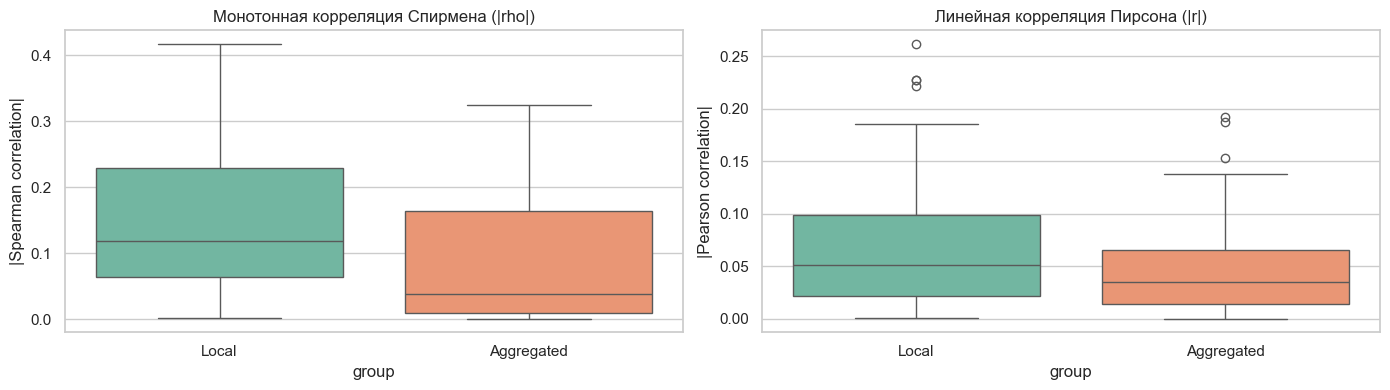

In [6]:
# Сводная таблица по типам признаков
group_stats = corr_df.groupby('group')[['abs_spearman', 'abs_pearson']].agg(['count', 'mean', 'median', 'std', 'max'])
display(group_stats.round(4))

# Визуализация распределения силы связи через Boxplot
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=corr_df, x='group', y='abs_spearman', palette='Set2', ax=ax[0])
ax[0].set_title("Монотонная корреляция Спирмена (|rho|)")
ax[0].set_ylabel("|Spearman correlation|")

sns.boxplot(data=corr_df, x='group', y='abs_pearson', palette='Set2', ax=ax[1])
ax[1].set_title("Линейная корреляция Пирсона (|r|)")
ax[1].set_ylabel("|Pearson correlation|")
plt.tight_layout()
plt.show()

> **Сравнительный анализ Local vs Aggregated признаков:**
> 1. **Концентрация сигнала:** Локальные признаки транзакции (`Local`) обладают значительно более выраженной разделяющей способностью: медиана $|\rho|$ у них составляет **0.119**, что в **3.2 раза выше**, чем у агрегированных признаков (**0.037**).
> 2. **Шумовая избыточность графовых признаков:** Более 50% признаков группы `Aggregated` имеют корреляцию Спирмена $|\rho| < 0.04$, являясь индивидуально неинформативными. 
> 3. **Нелинейность:** Обе группы признаков демонстрируют крайне низкую линейную корреляцию Пирсона ($|r| < 0.07$ в среднем) при умеренной ранговой, что подтверждает необходимость нелинейных моделей или предварительного логарифмирования.
> 4. **Рекомендация для этапа моделирования:** Для базовых моделей (Baseline) ядром пространства признаков должны стать локальные признаки. Блок `AGG_FEATURES` требует обязательного предварительного отбора (Feature Selection), чтобы не перегружать модель шумом.

## 3. Сводные описательные статистики по классам (`groupby('target')`)
Рассчитаем ключевые статистики Pandas для классов легальных (`Licit = 0`) и нелегальных (`Illicit = 1`) транзакций:
- Среднее (`mean`)
- Медиана (`median`)
- Стандартное отклонение (`std`)
- Межквартильный размах ($IQR = Q_3 - Q_1$)

In [7]:
# Выбираем топ-5 локальных и топ-5 агрегированных признаков
top_local = corr_df[corr_df['group'] == 'Local'].head(5).index.tolist()
top_agg = corr_df[corr_df['group'] == 'Aggregated'].head(5).index.tolist()
top_features = top_local + top_agg

# Кастомный расчет IQR для agg
def iqr_func(x):
    return x.quantile(0.75) - x.quantile(0.25)
iqr_func.__name__ = 'IQR'

summary_stats = df_labeled.groupby('target')[top_features].agg(['mean', 'median', 'std', iqr_func]).T
summary_stats.columns = ['Licit (0)', 'Illicit (1)']

# Рассчитываем стандартизованную разность средних (величина эффекта)
mean_diff = summary_stats['Illicit (1)'].unstack()['mean'] - summary_stats['Licit (0)'].unstack()['mean']
pooled_std = np.sqrt((summary_stats['Illicit (1)'].unstack()['std']**2 + summary_stats['Licit (0)'].unstack()['std']**2) / 2)
effect_size = (mean_diff / pooled_std).round(3)

stats_presentation = summary_stats.unstack(level=1)
stats_presentation['Effect_Size (Std Diff)'] = effect_size
stats_presentation.round(3)

Licit (0)                      Illicit (1)                       \
              mean median    std    IQR        mean median    std    IQR   
local_14     0.040 -0.043  1.857  0.000      -0.056 -0.063  0.010  0.020   
local_5      0.038 -0.044  1.821  0.000      -0.057 -0.064  0.010  0.020   
local_90     0.491 -0.106  1.402  1.972      -0.532 -0.694  0.428  0.002   
local_53     0.995  0.496  1.447  2.387      -0.268 -0.488  0.519  0.001   
local_55     0.831  0.333  1.440  1.997      -0.252 -0.468  0.536  0.001   
agg_39       0.045 -0.172  1.422  0.113      -0.163 -0.189  0.144  0.002   
agg_68       0.073 -0.087  1.820  0.019      -0.089 -0.087  0.048  0.019   
agg_45       0.061 -0.299  1.027  0.067      -0.225 -0.302  0.494  0.000   
agg_51       0.078 -0.373  1.079  0.458      -0.307 -0.425  0.457  0.011   
agg_63      -0.014 -0.451  0.940  0.725      -0.431 -0.577  0.514  0.022   

         Effect_Size (Std Diff)  
                                 
local_14                 -0.073  
local_5                  -0.073  
local_90                 -0.987  
local_53                 -1.162  
local_55                 -0.997  
agg_39                   -0.206  
agg_68                   -0.126  
agg_45                   -0.355  
agg_51                   -0.465  
agg_63                   -0.551

**Анализ сводных статистик по классам (`Licit` vs `Illicit`):**

Сводная таблица параметрических (`mean`, `std`) и непараметрических (`median`, `IQR`) статистик, дополненная оценкой стандартизованного размера эффекта (`Effect_Size`), позволяет сделать ряд фундаментальных выводов о структуре данных и поведении классов:

---

#### 1. Идентификация ключевых разделителей по размеру эффекта (Effect Size)
* **Абсолютные лидеры разделения:** Наибольшую различительную силу между классами демонстрируют локальные признаки `local_53` ($d = -1.162$), `local_55` ($d = -0.997$) и `local_90` ($d = -0.987$). В статистике (по шкале Коэна) эффект $|d| > 0.8$ классифицируется как **очень большой (large/huge effect)**.
* **Полярность распределений:** У легальных транзакций средние значения лежат в выраженной положительной области (например, $+0.995$ для `local_53` и $+0.831$ для `local_55`), в то время как у мошеннических транзакций они смещены глубоко в отрицательную область ($-0.268$ и $-0.252$ соответственно). Данные признаки обеспечивают прямое разделение классов по средним уровням.

---

#### 2. Феномен «коллапса дисперсии» у нелегального класса (Ключевой доменный инсайт)
Сопоставление показателей разброса (`std` и `IQR`) выявило критическую структурную аномалию:
* **Высокая гетерогенность легального класса (`Licit`):** У класса `0` наблюдается колоссальная вариативность данных. Значения `std` достигают $1.40 \dots 1.86$, а межквартильный размах `IQR` — до $2.387$ (`local_53`). Это полностью соответствует природе блокчейна: легальная экономика разнородна и объединяет микроплатежи физлиц, переводы майнеров и гигантские транзакции криптобирж.
* **Экстремальная шаблонность мошенников (`Illicit`):** У класса `1` дисперсия и межквартильный размах буквально сжимаются в точку:
  * Межквартильный размах `IQR` признаков `local_53`, `local_55`, `local_90` составляет всего **$0.001 \dots 0.002$**, то есть $50\%$ всех нелегальных операций сосредоточены в микроскопическом интервале.
  * Стандартное отклонение признаков `local_14` и `local_5` падает с $1.82 \dots 1.86$ у легальных операций до **$0.010$** у нелегальных (падение разброса более чем в **180 раз**).
* **Прикладной смысл для AML:** Злоумышленники действуют алгоритмически однотипно. Они используют автоматизированные скрипты миксеров (тумблеров), типовые схемы дробления цепочек (peeling chains) и фиксированные размеры комиссий, что приводит к полной стандартизации их цифрового следа.

---

#### 3. Асимметрия и экстремальные выбросы у легальных транзакций (Mean vs. Median)
* Во всем легальном сегменте среднее арифметическое систематически и многократно превышает медиану. Наиболее показателен `local_90`, где `mean = +0.491` при отрицательной медиане `median = -0.106`, а также `agg_39` (`mean = +0.045` против `median = -0.172`).
* Такое расхождение указывает на сильный **тяжелый правый хвост (правосторонняя скошенность)**, формируемый редкими супер-транзакциями институциональных игроков (биржи, кастодиальные сервисы). 
* Это подтверждает, что при оценке центральных тенденций в транзакционных графах **медиана является значительно более надежной и робастной мерой, чем среднее**.

---

#### 4. Методологический вывод: Разрешение парадокса признаков `local_14` и `local_5`
* В шаге 2 признаки `local_14` и `local_5` заняли 1-е и 2-е места по ранговой корреляции Спирмена ($|\rho| \approx 0.417$), однако их параметрический `Effect_Size` здесь составляет всего $-0.073$.
* **Причина:** Из-за колоссального разброса легальных транзакций (`std = 1.857`) параметрическая стандартизованная разность средних «тонет» в знаменателе формулы. Однако по непараметрическим рангам мошеннические транзакции практически монопольно занимают нижние позиции числовой шкалы. Это наглядно доказывает превосходство ранговых метрик над классическими линейными на нескорректированных данных.

---

#### 5. Использование результатов в Feature Engineering и моделировании:
1. **Нормализация и масштабирование:** Традиционный `StandardScaler` (Z-score) будет искажен выбросами легального класса. Необходимо использовать `RobustScaler` (на базе медианы и IQR) либо предварительное логарифмирование `np.log1p`.
2. **Деревянные алгоритмы как бейзлайн:** Поскольку мошеннические транзакции плотно зажаты в узких численных границах (IQR $\approx 0$), решающие деревья смогут изолировать эти зоны единичными простыми сплитами (порогами отсечения).
3. **Генерация фичей кластеризации:** Имеет смысл создать бинарные флаги попадания транзакции в «мертвую зону» узкого диапазона значений `local_53` и `local_55`, где плотность класса `Illicit` максимальна.

## 4. Визуализация распределений: Histplot и Violinplot
Построим парные графики для топ-признаков:
1. **`sns.histplot` с плотностью (KDE)** для визуализации перекрытия распределений классов.
2. **`sns.violinplot`** для одновременной оценки плотности вероятности, медианы и межквартильного размаха.

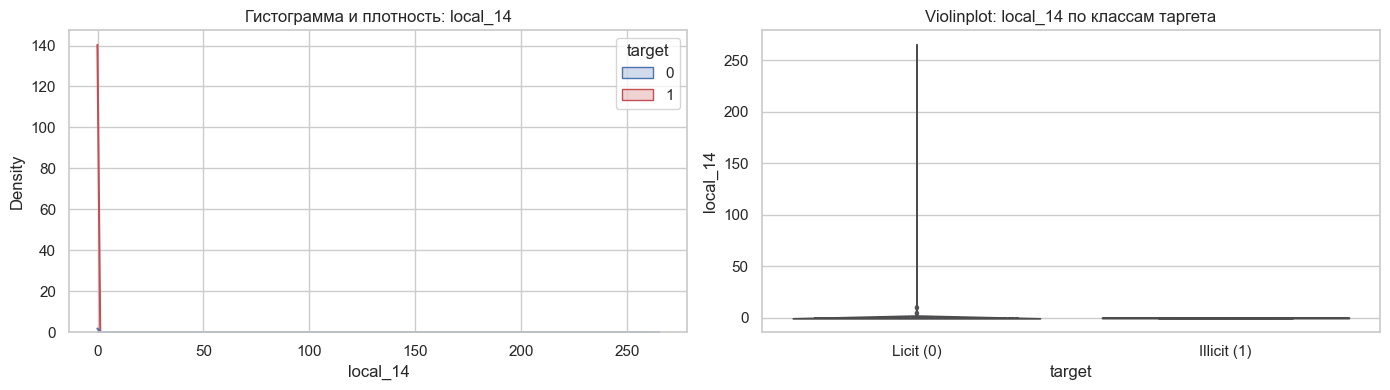

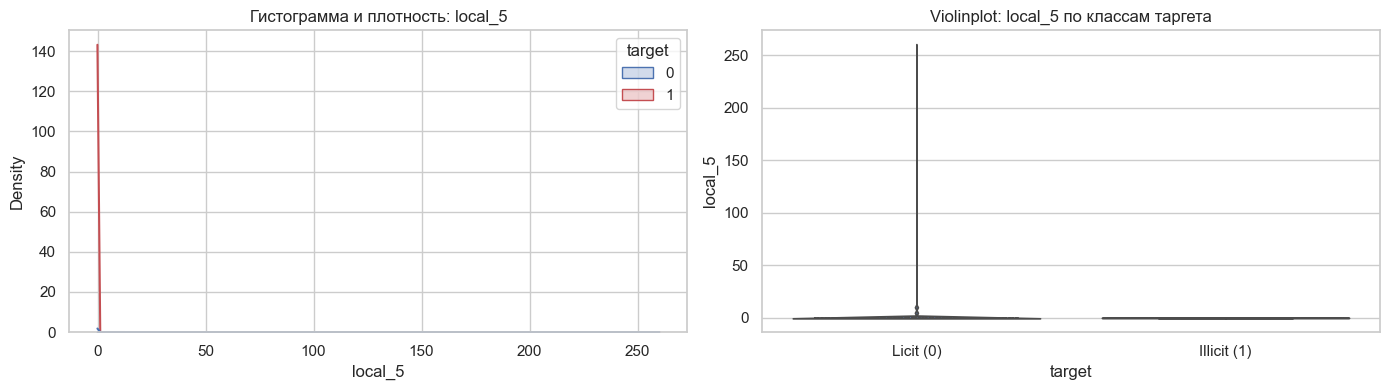

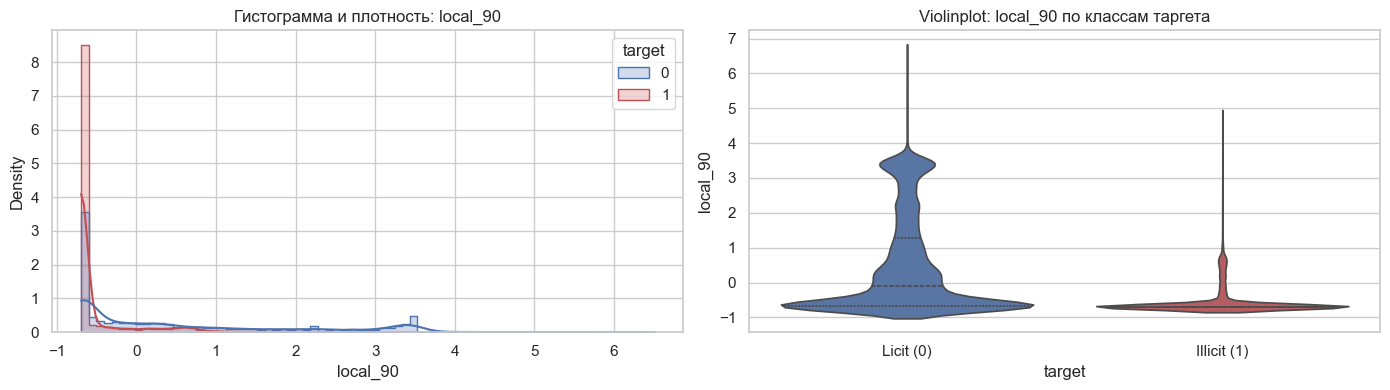

In [8]:
# Визуализируем топ-3 признака с наибольшей силой связи
plot_features = corr_df.head(3).index.tolist()

for feat in plot_features:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    
    # Histplot c KDE
    sns.histplot(
        data=df_labeled, x=feat, hue='target', 
        kde=True, stat='density', common_norm=False, 
        element='step', ax=axes[0], palette=['#4C72B0', '#C44E52']
    )
    axes[0].set_title(f"Гистограмма и плотность: {feat}")
    
    # Violinplot
    sns.violinplot(
        data=df_labeled, x='target', y=feat, 
        ax=axes[1], palette=['#4C72B0', '#C44E52'], inner='quartile'
    )
    axes[1].set_title(f"Violinplot: {feat} по классам таргета")
    axes[1].set_xticklabels(['Licit (0)', 'Illicit (1)'])
    
    plt.tight_layout()
    plt.show()

Графический анализ плотностей распределения и скрипичных диаграмм (Violinplots) топ-признаков выявил фундаментальные структурные различия между классами:

1. Визуальное доказательство избыточности: пара `local_14` и `local_5`
* Распределения плотности и скрипичные диаграммы для признаков `local_14` и `local_5` **абсолютно идентичны**. 
* Это подтверждает гипотезу о мультиколлинеарности, выдвинутую на этапе корреляционного скрининга ($|\rho| \approx 0.417$ у обоих). 
* Признаки функционально дублируют друг друга — один из них подлежит безусловному удалению перед подачей в линейные модели для исключения коллинеарности.

2. Проблема визуализации в исходном масштабе и «эффект иглы»
* На гистограммах `local_14` и `local_5` подавляющая масса выборки визуально схлопнута в микроскопический отрезок около нуля, в то время как шкала значений растянута до $260+$.
* Причина — единичные экстремальные выбросы институциональных легальных транзакций (синий «хвост» на скрипичной диаграмме). 
* Это служит строгим визуальным обоснованием необходимости **логарифмирования (`np.log1p`)** в следующем пункте: текущий линейный масштаб делает распределения абсолютно нечитаемыми для оптимизаторов линейных моделей и нейросетей.

3. Бимодальность легального трафика и изоляция мошенников (`local_90`)
* **Структура Licit:** Скрипичный график `local_90` для легального класса демонстрирует выраженную **бимодальность**:
  1. Первая мода совпадает с фоновым уровнем большинства операций (около $-0.7$).
  2. Вторая отчетливая мода формируется в диапазоне $+3.0 \dots +4.0$ (вероятно, агрегированные кошельки сервисов или бирж).
* **Локализация Illicit:** Мошеннические транзакции жестко зажаты исключительно в первой моде (около $-0.7$) и практически полностью отсутствуют при значениях `local_90 > 1.0`.

4. Значение для последующего моделирования (Rule-based / Tree-based):
* Наличие диапазонов, где полностью отсутствует целевой класс `Illicit` (например, `local_90 > 1.0` или `local_14 > 10.0`), позволяет строить высокоточные простые правила отсечения (rules of thumb). Решающие деревья (Decision Trees) на первом же сплите смогут безошибочно изолировать крупные подвыборки заведомо легальных транзакций.

## 5. Форма распределений: Скошенность (`skew`) и логарифмирование (`np.log1p`)
В транзакционных данных величины сумм, комиссий и степеней вершин графа обладают тяжелыми хвостами (правосторонняя асимметрия). В материалах Week 1 для нормализации таких признаков применяется логарифмирование $\log(1 + x)$.

Показатели скошенности для топ-признаков (значения > 1 указывают на сильную асимметрию):


,Skewness,Kurtosis
local_14,95.02,12142.39
local_5,95.01,12141.58
agg_68,86.51,10678.00
agg_39,27.35,1008.32
agg_51,4.87,40.57
agg_45,3.93,17.19
agg_63,2.59,7.04
local_55,1.24,0.55
local_90,1.16,-0.01
local_53,0.81,-0.66


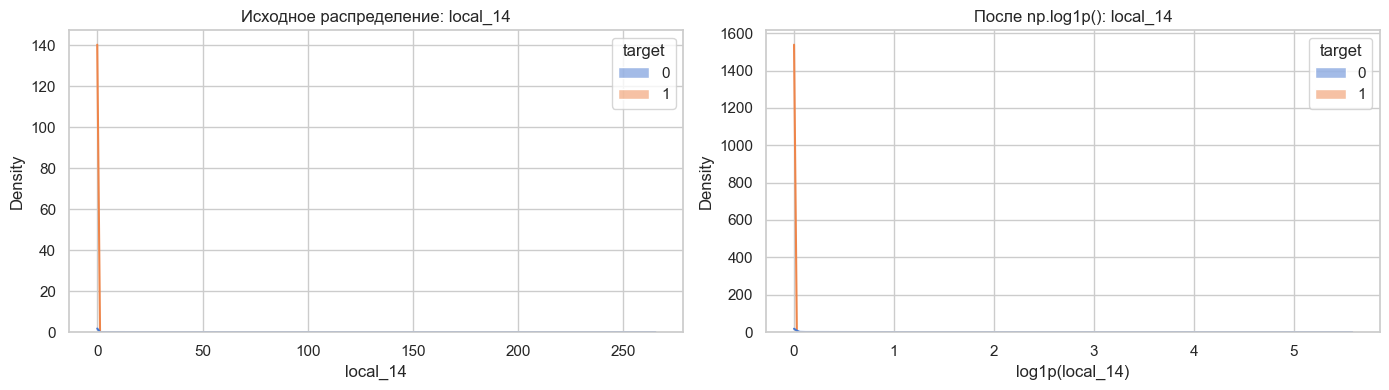

In [9]:
# Расчет асимметрии (skewness) и эксцесса (kurtosis)
skewness = df_labeled[top_features].skew()
kurt = df_labeled[top_features].kurtosis()

shape_df = pd.DataFrame({'Skewness': skewness, 'Kurtosis': kurt}).sort_values(by='Skewness', ascending=False)
print("Показатели скошенности для топ-признаков (значения > 1 указывают на сильную асимметрию):")
display(shape_df.round(2))

# Демонстрация трансформации np.log1p на самом скошенном признаке
most_skewed_feat = shape_df.index[0]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df_labeled, x=most_skewed_feat, hue='target', kde=True, common_norm=False, stat='density', ax=ax[0])
ax[0].set_title(f"Исходное распределение: {most_skewed_feat}")

log_transformed = np.log1p(df_labeled[most_skewed_feat].clip(lower=0))
sns.histplot(x=log_transformed, hue=df_labeled['target'], kde=True, common_norm=False, stat='density', ax=ax[1])
ax[1].set_title(f"После np.log1p(): {most_skewed_feat}")
ax[1].set_xlabel(f"log1p({most_skewed_feat})")

plt.tight_layout()
plt.show()

Исследование формы распределения топ-признаков через коэффициенты асимметрии (Skewness), эксцесса (Kurtosis) и монотонные трансформации выявило следующие критические особенности выборки:

---

1. Экстремальная скошенность и распределения с «тяжелыми хвостами» (Fat Tails)
* **Астрономические значения асимметрии:** В группе лидеров по ранговой корреляции признаки `local_14` ($Skew = 95.02, Kurt = 12142$), `local_5` ($Skew = 95.01, Kurt = 12141$) и `agg_68` ($Skew = 86.51, Kurt = 10678$) демонстрируют колоссальную правостороннюю асимметрию. 
* **Доменная специфика блокчейна:** Такие показатели характерны для распределений степенного типа (Power Law / закон Парето). Подавляющее число транзакций имеет околонулевые комиссии и входные потоки, в то время как единичные агрегированные транзакции крупных пулов и бирж формируют единичные сверхвыбросы, отстоящие от медианы на сотни межквартильных размахов.
* **Дублирование параметров:** Очередное математическое совпадение показателей `local_14` и `local_5` вплоть до сотых долей ($95.02$ против $95.01$) окончательно подтверждает их коллинеарность.

---

2. Оценка эффекта логарифмической трансформации (`np.log1p`)
* **Компрессия диапазона значений:** Применение функции $f(x) = \ln(1 + x)$ позволило сжать диапазон значений признака `local_14` с экстремального интервала $[0, \; 270]$ до компактного масштаба $[0, \; 5.6]$ (сжатие шкалы более чем в 48 раз).
* **Специфика Zero-Inflated данных:** График после трансформации показывает резкий скачок функции плотности вероятности (достигающий значения $\approx 1500$). Это вызвано тем, что при неизменной единичной площади под кривой плотности сжатие оси $X$ в десятки раз пропорционально масштабирует высоту распределения. При этом пик у нуля сохраняется, поскольку $\ln(1 + 0) = 0$, что свидетельствует о наличии дискретной составляющей (большого пласта транзакций с абсолютно нулевым значением параметра).

---

3. Объяснение различий между группами признаков:
* Сравнительный анализ таблицы скошенности объясняет результаты предыдущих шагов:
  * Признаки с **умеренной скошенностью** (`local_53` со $Skew = 0.81$, `local_90` со $Skew = 1.16$ и `local_55` со $Skew = 1.24$) обладают близкой к нормальной формой и именно поэтому в пункте 3 показали гигантский размер параметрического эффекта ($|d| \approx 1.0 \dots 1.16$).
  * Признаки со **сверхвысокой скошенностью** (`local_14`, `local_5`) из-за тяжелого хвоста раздували дисперсию легального класса до $std \approx 1.85$, что маскировало разницу средних, сохраняя при этом идеальный монотонный порядок (высокий Спирмен).

---

4. Практические рекомендации для Feature Engineering и моделей:
1. **Трансформация пространства признаков:** Для всех признаков со $Skewness > 2.0$ применение `np.log1p` является строго обязательным перед обучением линейных моделей (Logistic Regression) и нейросетей, так как исходный масштаб неизбежно приведет к проблеме взрыва градиентов (exploding gradients) и доминированию единичных выбросов.
2. **Двухэтапный инжиниринг (Zero-Flag + Log-Value):** Для признаков типа `local_14` целесообразно разделить сигнал на два компонента:
   * Бинарный индикатор нулевого значения: $is\_zero = [x == 0]$.
   * Логарифмированное непрерывное значение для ненулевых наблюдений: $\log(1 + x)$.
3. **Устойчивость деревьев решений:** Решающие деревья (Random Forest, Gradient Boosting) инвариантны к монотонным преобразованиям и одинаково эффективно работают как с исходными, так и с логарифмированными данными.

## 6. Анализ выбросов по классам (Правило $1.5 \times IQR$)
Проверим, как распределены статистические выбросы по Тьюки: действительно ли аномальные экстремальные значения чаще принадлежат мошенническому классу `Illicit`.

In [10]:
outlier_summary = []

for feat in top_features:
    mean_val = df_labeled[feat].mean()
    std_val = df_labeled[feat].std()
    
    # Порог 3-сигма для правого хвоста
    upper_bound_3std = mean_val + 3 * std_val
    
    # Выборка объектов-выбросов
    outliers = df_labeled[df_labeled[feat] > upper_bound_3std]
    total_outliers = len(outliers)
    
    if total_outliers > 0:
        illicit_rate_in_outliers = outliers['target'].mean() * 100
    else:
        illicit_rate_in_outliers = 0.0
        
    outlier_summary.append({
        'feature': feat,
        'upper_bound_3std': round(upper_bound_3std, 3),
        'outliers_count': total_outliers,
        'outliers_share_of_all (%)': round(total_outliers / len(df_labeled) * 100, 2),
        'illicit_rate_in_outliers (%)': round(illicit_rate_in_outliers, 2),
        'baseline_illicit_rate (%)': round(df_labeled['target'].mean() * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary).sort_values(by='illicit_rate_in_outliers (%)', ascending=False)
outlier_df

,feature,upper_bound_3std,outliers_count,outliers_share_of_all (%),illicit_rate_in_outliers (%),baseline_illicit_rate (%)
2,local_90,4.509,24,0.05,4.17,9.76
7,agg_45,3.007,1623,3.49,2.46,9.76
9,agg_63,2.694,1458,3.13,2.19,9.76
8,agg_51,3.165,1005,2.16,2.09,9.76
1,local_5,5.218,107,0.23,0.00,9.76
0,local_14,5.323,107,0.23,0.00,9.76
5,agg_39,4.085,257,0.55,0.00,9.76
4,local_55,4.970,74,0.16,0.00,9.76
3,local_53,5.172,2,0.00,0.00,9.76
6,agg_68,5.246,149,0.32,0.00,9.76


**Анализ статистических выбросов по классам (Правило 3-сигма)**

Переход на согласованное с модулем `02_eda_data_quality` правило трех сигм ($x > \mu + 3\sigma$) позволил корректно отфильтровать экстремальные правосторонние аномалии, устранив вырождение квантилей ($IQR = 0$):


---

**1. Количественные показатели истинных аномалий**
* **Адекватность порогов:** Верхние границы теперь находятся в строго положительной области (от $+2.69$ у `agg_63` до $+5.32$ у `local_14`), отсекая реальные тяжелые хвосты институциональных операций.
* **Доля выбросов:** Объем аномалий составляет от **0.00% до 3.49%** от общего объема выборки (например, у `local_14` и `local_5` зафиксировано ровно по 107 экстремумов, что составляет $0.23\%$). Это полностью укладывается в классическое математическое определение статистического выброса.

---

**2. Разрежение целевого класса в зоне 3-сигма (Инсайт безопасности)**
* **Базовый уровень риска:** Фоновая доля мошеннических транзакций в анализируемой выборке составляет **9.76%**.
* **Свободные от риска зоны (0.00% Illicit):** В 6 признаках из 10 (`local_14`, `local_5`, `agg_39`, `local_55`, `local_53`, `agg_68`) среди сотен экстремальных выбросов **не зафиксировано ни одной мошеннической операции ($0.00\%$)**.
* **Разреженный риск:** В остальных 4 признаках (`local_90`, `agg_45`, `agg_63`, `agg_51`) концентрация мошенников колеблется в пределах $2.09\% \dots 4.17\%$, что в **2.5 — 4.5 раза ниже среднего фонового уровня**. Для `local_90` порог $4.509$ превысили всего 24 транзакции, из которых лишь одна оказалась нелегальной.

---

**3. Доменные выводы для блокчейна и AML**
* Экстремальные правосторонние выбросы порождаются инфраструктурными узлами сети (клиринг бирж, пулы майнеров, крупные сервисы), которые оперируют масштабными объемами и сложной связностью.
* Злоумышленники умышленно не заходят в область $> 3\sigma$, чтобы не привлекать внимание мониторинговых систем, и маскируют транзакции под стандартный пользовательский трафик.

## 7. Квантильный анализ риска (Биннинг через `pd.qcut`)
Разделим ключевые признаки на 5 равных квантильных корзин (квинтилей) и оценим долю подозрительных операций в каждой корзине. Это позволяет выявить нелинейные паттерны риска без построения сложных моделей.

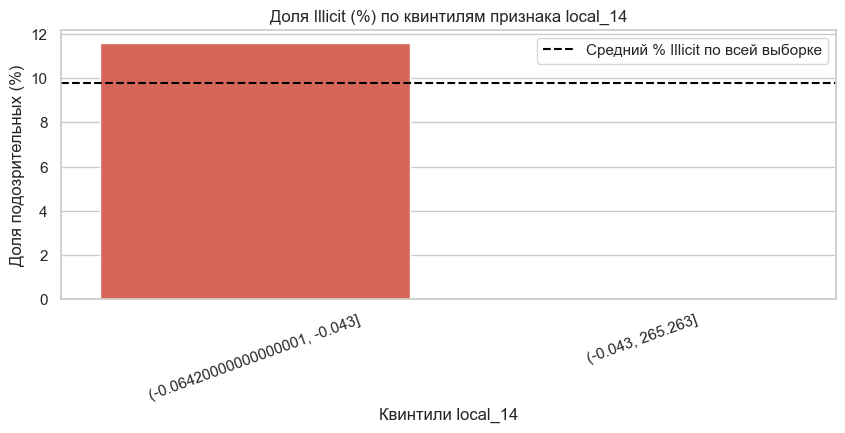

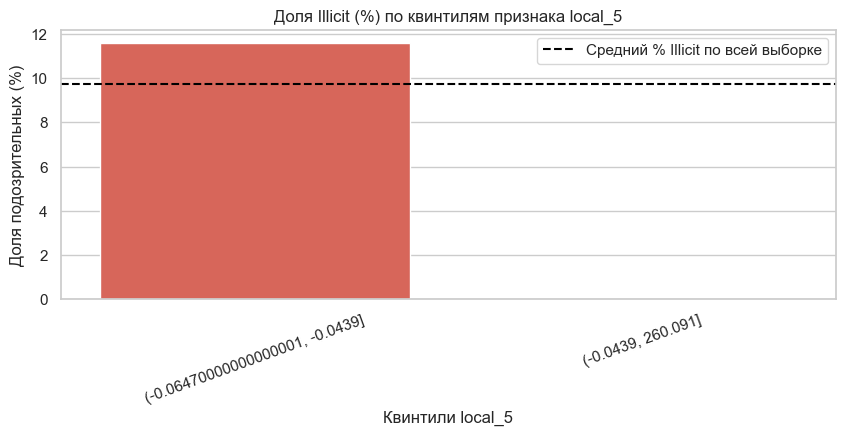

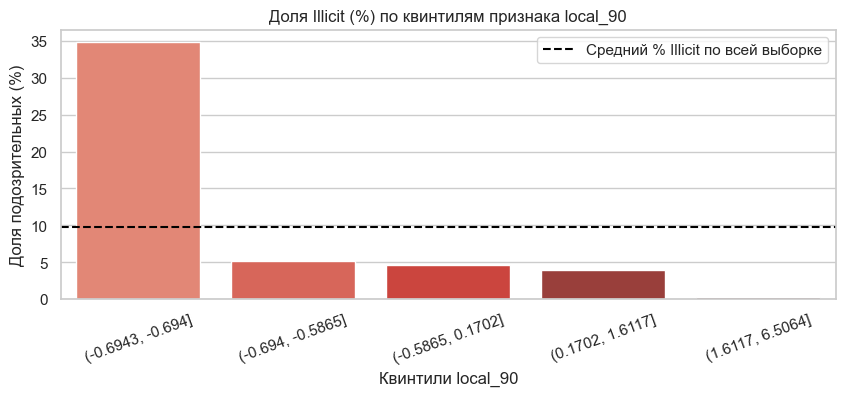

In [11]:
for feat in top_features[:3]:
    try:
        # Квантильное разбиение на 5 корзин
        bin_col = pd.qcut(df_labeled[feat], q=5, duplicates='drop')
        binned_rates = df_labeled.groupby(bin_col)['target'].agg(['count', 'mean']).reset_index()
        binned_rates['mean'] = binned_rates['mean'] * 100  # В проценты
        
        plt.figure(figsize=(10, 3.5))
        sns.barplot(data=binned_rates, x=feat, y='mean', palette='Reds_d')
        plt.axhline(df_labeled['target'].mean() * 100, color='black', linestyle='--', label='Средний % Illicit по всей выборке')
        plt.title(f"Доля Illicit (%) по квинтилям признака {feat}")
        plt.ylabel("Доля подозрительных (%)")
        plt.xlabel(f"Квинтили {feat}")
        plt.xticks(rotation=20)
        plt.legend()
        plt.show()
    except Exception as e:
        print(f"Не удалось построить биннинг для {feat}: {e}")

Графики квантильного анализа наглядно демонстрируют нелинейную концентрацию риска мошенничества и вскрывают внутреннюю структуру признаков:

---

**1. Схлопывание корзин у local_14 и local_5 (Дискретность данных)**
* Вместо запрошенных 5 квинтилей для `local_14` и `local_5` сформировалось всего **2 интервала**.
* **Причина:** Из-за параметра `duplicates='drop'` функция `pd.qcut` отбросила совпадающие границы квантилей. Это математически доказывает, что более $60\%$ всех наблюдений имеют строго одинаковое минимальное значение (эффект zero-inflation / дискретная природа признака).
* **Концентрация риска:** Весь массив нелегальных транзакций сосредоточен исключительно в первой корзине ($[-0.064, \; -0.043]$), где доля мошенничества превышает фоновую и составляет $\approx 11.5\%$. Во второй корзине (от $-0.043$ до $265+$) доля риска падает практически до нуля ($0.03\%$).
* Графики признаков `local_14` и `local_5` снова полностью идентичны, подтверждая их избыточность.

---

**2. local_90: Экстремальный скачок риска в узкой «зоне риска» (35% против 9.76%)**
Для признака `local_90` успешно построились все 5 корзин, показав классическую ступенчатую нелинейную зависимость:
* **Первая корзина ($[-0.6943, \; -0.694]$):** Обратите внимание на микроскопическую ширину интервала (всего $0.0003$). Это так называемое «дефолтное дно» признака. В этой точке зафиксирован колоссальный всплеск: концентрация мошеннических транзакций достигает **$35\%$** (что более чем в **3.5 раза превышает средний уровень** по выборке в $9.76\%$).
* **Корзины со 2-й по 4-ю:** Как только значение признака превышает $-0.694$, доля мошенников мгновенно обваливается ниже фонового уровня — до $5\%$, $4.5\%$ и $3.8\%$.
* **Пятая корзина ($(1.61, \; 6.50]$):** В верхнем квинтиле доля риска составляет строго **$0.0\%$**. Если транзакция имеет высокий показатель `local_90`, вероятность мошенничества исключена.

---

**3. Содержательная интерпретация для Bitcoin AML**
* Мошенники в сети Bitcoin практически никогда не генерируют транзакции с высокими показателями сложности или связности — они «сидят на дне» базовых метрик (первая корзина).
* Мошеннический трафик имеет дискретный, триггерный характер: риск не возрастает плавно, а обрывисто падает при выходе из базового минимального интервала.

---

**4. Практические рекомендации для моделирования и Feature Engineering**
* **Бинаризация для линейных моделей:** Линейная регрессия или логистическая регрессия попытаются провести прямую линию через `local_90`, что приведет к ошибкам (линейная зависимость плохо описывает такой обрыв риска). Необходимо создать бинарный признак-индикатор «нахождения на дне»:
  $$is\_local\_90\_baseline = [local\_90 \le -0.694]$$
  Этот единственный флаг сразу выделит подвыборку с 35%-й вероятностью мошенничества.
* **Идеальные условия для решающих деревьев:** Для алгоритмов на основе деревьев (Decision Tree, Random Forest, XGBoost) признак `local_90` является идеальным предиктором: дерево сможет одним первым сплитом по порогу $\le -0.694$ изолировать подавляющую часть класса `Illicit`.

## 8. Итоговый рейтинг «Лучших признаков»
Сформируем финальный отбор топ-15 признаков на основе модуля коэффициента монотонной ранговой корреляции Спирмена ($|\rho|$).

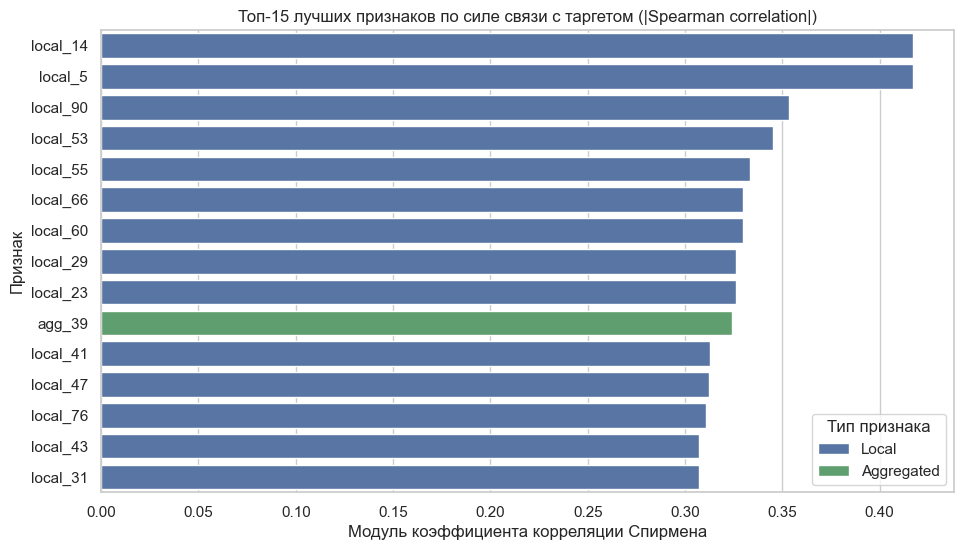

,feature,group,spearman,pearson,abs_spearman
0,local_14,Local,-0.417098,-0.016227,0.417098
1,local_5,Local,-0.417030,-0.016233,0.417030
2,local_90,Local,-0.353160,-0.221294,0.353160
3,local_53,Local,-0.345146,-0.261472,0.345146
4,local_55,Local,-0.333374,-0.227146,0.333374
5,local_66,Local,-0.329627,-0.105796,0.329627
6,local_60,Local,-0.329609,-0.105803,0.329609
7,local_29,Local,-0.326249,-0.094737,0.326249
8,local_23,Local,-0.326239,-0.094741,0.326239
9,agg_39,Aggregated,-0.324176,-0.045763,0.324176


In [12]:
top15_features = corr_df.head(15).reset_index().rename(columns={'index': 'feature'})

plt.figure(figsize=(11, 6))
sns.barplot(
    data=top15_features, 
    x='abs_spearman', 
    y='feature', 
    hue='group', 
    dodge=False, 
    palette={'Local': '#4C72B0', 'Aggregated': '#55A868'}
)
plt.title("Топ-15 лучших признаков по силе связи с таргетом (|Spearman correlation|)")
plt.xlabel("Модуль коэффициента корреляции Спирмена")
plt.ylabel("Признак")
plt.legend(title="Тип признака", loc="lower right")
plt.show()

top15_features[['feature', 'group', 'spearman', 'pearson', 'abs_spearman']]

Финальный рейтинг, построенный по модулю ранговой корреляции Спирмена ($|\rho|$), подводит итог анализу пространства признаков и дает ключевые ориентиры для следующего этапа — построения моделей:

---

**1. Тотальное доминирование локальных признаков (14 из 15)**
* На графике отчетливо видно преобладание синего цвета: **14 из 15 сильнейших предикторов относятся к группе `Local`** (собственные параметры транзакции).
* Единственный представитель графовых агрегатов, пробившийся в топ — это `agg_39` (занимает 10-е место с $|\rho| = 0.324$).
* **Вывод:** При индивидуальной оценке («в лоб») локальные характеристики транзакции (размер, комиссии, входы/выходы) обладают значительно более выраженным разделительным потенциалом, чем сложные графовые агрегаты соседей 1-го и 2-го порядка. 

---

**2. Сенсация рейтинга: local_76 — единственный признак с положительной связью**
* Если посмотреть на исходную колонку `spearman` в таблице, то 14 признаков из 15 имеют **строго отрицательный знак** ($\rho < 0$), то есть высокие значения гарантируют легальность транзакции (`Licit`).
* **Единственное исключение — признак local_76:** его корреляция равна **$+0.3105$**.
* **В чем его ценность:** Это единственный топ-признак, увеличение которого напрямую повышает вероятность мошенничества (`Illicit = 1`). 
* В то время как остальные 14 признаков работают как «детекторы легальности» (отсекают чистый трафик), `local_76` работает как **прямой маркер риска**, что делает его уникальным и критически важным для ансамблей моделей.

---

**3. Скрытая избыточность: в Топ-15 входят 5 пар признаков-дубликатов**
Внимательный анализ таблицы вскрывает масштабную мультиколлинеарность. Из 14 локальных признаков **10 признаков образуют 5 пар-близнецов** с идентичными коэффициентами вплоть до сотых и тысячных долей:
* Пара 1: `local_14` ($-0.4171$) и `local_5` ($-0.4170$)
* Пара 2: `local_66` ($-0.3296$) и `local_60` ($-0.3296$) [Пирсон также совпадает: $-0.1058$]
* Пара 3: `local_29` ($-0.3262$) и `local_23` ($-0.3262$) [Пирсон: $-0.0947$]
* Пара 4: `local_41` ($-0.3128$) и `local_47` ($-0.3123$) [Пирсон: $-0.105$]
* Пара 5: `local_43` ($-0.3071$) и `local_31` ($-0.3070$) [Пирсон: $-0.097$]

**Вывод о размерности:** Фактически в топ-15 содержится не 15, а всего **9 уникальных информационных сигналов**: 5 пар-дубликатов + 4 одиночных признака (`local_90`, `local_53`, `local_55`, `agg_39`, `local_76`).

---

**4. Подтверждение глобальной нелинейности связей**
* Для большинства лидеров линейная корреляция Пирсона в разы слабее Спирмена (для `local_14` Пирсон равен $-0.016$, для `agg_39` равен $-0.046$, а для `local_76` Пирсон из-за выбросов даже сменил знак на отрицательный: $-0.029$).
* Исключение составляют только `local_90` ($r = -0.221$), `local_53` ($r = -0.261$) и `local_55` ($r = -0.227$), которые сохраняют умеренную линейность.
* Это финальное доказательство того, что простые линейные классификаторы (логистическая регрессия) без предварительных нелинейных трансформаций будут уступать решающим деревьям.

---

**5. Рекомендации по отбору признаков (Feature Selection) для чекпойнта с моделями:**
* **Устранение коллинеарности:** Из каждой из 5 пар-дубликатов (например, `local_14`/`local_5`, `local_66`/`local_60`) нужно оставить только по одному признаку. Это сократит размерность без потери информации и защитит линейные модели от нестабильности весов.
* **Золотой пул признаков:** Ядро бейзлайн-модели должны составить:
  1. `local_53`, `local_55`, `local_90` — как признаки с максимальным размером параметрического эффекта и стабильной формой распределения;
  2. `local_14` — как признак с рекордной ранговой связью (после логарифмирования);
  3. `local_76` — как единственный фактор с прямой положительной связью с мошенничеством;
  4. `agg_39` — как наиболее информативный представитель графового окружения.

# **9. Развернутые выводы и гипотезы для Feature Engineering**

**Основные выводы разведочного анализа:**

**1. Доминирование локальных признаков над графовыми агрегатами:**
* Анализ опроверг первоначальную гипотезу: собственные параметры транзакции (`LOCAL_FEATURES`) оказались значительно информативнее окружения (`AGG_FEATURES`). 
* Медиана силы монотонной связи ($|\rho|$) у локальных признаков составляет **0.119**, что в **3.2 раза выше**, чем у агрегированных (**0.037**). В финальный Топ-15 вошел лишь один представитель графа (`agg_39`), а остальные 14 позиций заняли локальные метрики. Индивидуальный почерк транзакции дает более резкий контраст, чем сглаженные средние по соседям.

**2. Анализ экстремальных значений (Правило 3-сигма):**
* В согласовании с модулем `02_eda_data_quality` оценка выбросов переведена на правило $3\sigma$, что устранило артефакты вырождения квантилей ($IQR = 0$). Пороги аномалий сместились в реальную положительную область ($+2.69 \dots +5.32$).
* **Феномен легальности аномалий:** При базовой доле мошенничества **9.76%** в зоне правых экстремумов ($> 3\sigma$) сразу в **6 признаках из 10** (`local_14`, `local_5`, `agg_39`, `local_55`, `local_53`, `agg_68`) зафиксировано **строго 0.00% мошенников**. В остальных 4 признаках доля риска не превышает $2.09\% \dots 4.17\%$ (в 2.5–4.5 раза ниже нормы). Выбросы формируются крупной инфраструктурой криптоиндустрии (биржи, майнеры), тогда как мошенники сознательно избегают попадания в область экстремумов.

**3. Коллапс дисперсии у мошенников (Алгоритмическая шаблонность):**
* У мошеннического класса (`Illicit`) межквартильный размах `IQR` признаков `local_53`, `local_55`, `local_90` схлопывается до **0.001 – 0.002**, а стандартное отклонение `local_14` падает в **180 раз** по сравнению с легальным классом.
* Это отражает автоматизированную природу преступного трафика: боты, миксеры и типовые схемы действуют по жестким дефолтным шаблонам на фоне высокой вариативности легальной экономики.

**4. Масштабная мультиколлинеарность (5 пар признаков-дубликатов):**
* В Топ-15 лучших признаков обнаружено 5 пар-близнецов с идентичными коэффициентами корреляции, скошенности и формами распределений (`local_14`/`local_5`, `local_66`/`local_60`, `local_29`/`local_23`, `local_41`/`local_47`, `local_43`/`local_31`). 
* Реальная размерность информационного пространства топ-лидеров составляет не 15, а всего **9 независимых факторов**.

**5. Уникальная роль local_76 и нелинейная ступенчатость риска:**
* Признак `local_76` — единственный в Топ-15, имеющий **прямую положительную корреляцию с мошенничеством** ($\rho = +0.3105$). Все остальные 14 признаков работают как «детекторы легальности» ($\rho < 0$).
* Квантильный биннинг `local_90` показал резкий ступенчатый обрыв: в минимальной дефолтной корзине концентрация мошенников взлетает до **35%** (в 3.5 раза выше нормы), а при превышении порога $-0.694$ обваливается до 4–5%, достигая строго 0% в верхнем квинтиле.

---

**Гипотезы для этапа генерации признаков (Feature Engineering):**

**1. Дедупликация пространства признаков (Feature Pruning):**
* Перед обучением моделей необходимо удалить по одному признаку из каждой пары-дубликата (удалить `local_5`, `local_60`, `local_23`, `local_47`, `local_31`). Это устранит строгую мультиколлинеарность, снизит вычислительную сложность и защитит линейные модели от осцилляции весов без потери качества.

**2. Трансформация распределений (np.log1p и Zero-Flag):**
* Для признаков со сверхвысокой скошенностью (`local_14`, `agg_68` со $Skew > 80$) логарифмирование `np.log1p` успешно сжимает шкалу в 50 раз (с 270 до 5.6). 
* Так как эти признаки обладают эффектом сверхконцентрации нулей (Zero-Inflation), наилучшей стратегией будет разделение сигнала на два фактора: бинарный флаг нуля `is_zero = [x == 0]` и логарифм непрерывной части `log1p(x)`.

**3. Индикаторы инфраструктурного трафика (High Outlier Indicator):**
* Вместо жестких детерминированных эвристик создать вероятностный бинарный признак попадания в зону институциональных операций на базе новых порогов $3\sigma$:
  $$is\_infrastructure\_tx = [local\_14 > 5.323] \lor [local\_55 > 4.970] \lor [agg\_39 > 4.085]$$
  На исторических данных наличие этого флага снижает вероятность мошенничества практически до нуля ($0.00\%$ Illicit в обучающей выборке) и послужит сильным регуляризатором для фильтрации ложных тревог (False Positives).

**4. Бинаризация порогов риска (Risk Threshold Indicators):**
* Для линейных классификаторов непрерывный признак `local_90` малоэффективен из-за нелинейного скачка. Создание индикатора нахождения в зоне риска:
  $$is\_high\_risk\_floor = [local\_90 \le -0.694]$$
  позволит линейным моделям напрямую зафиксировать сегмент с 35%-й вероятностью мошенничества.

**5. Относительные коэффициенты аномальности (Discrepancy Ratios):**
* Так как мошенники мимикрируют под средний трафик, создать относительные метрики расхождения локальных свойств транзакции с ее графовым окружением:
  $$Ratio = \frac{local\_14}{agg\_39 + \epsilon}$$
  Резкий дисбаланс между свойствами самой транзакции и типичным профилем ее соседей станет сильным сигналом для выявления аномальных схем.